In [1]:
import numpy as np
from importlib import reload
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import pandas as pd
from scipy.stats import t, truncnorm
import joblib
%matplotlib widget

This is a tutorial on how to use a pre-trained emulator and testing it with new or pre-derived parameters.

We will load PCA modes, validation parameters, prospector tool

Depending on where you put the custom_prospector_tool.py, you might not need the code block below; 

In [2]:
module_path = Path('..').resolve()
if str(module_path) not in sys.path:
    sys.path.insert(0, str(module_path))

We import `custom_prospector_tools.py` since it has some useful functions for us

In [25]:
import custom_prospector_tools as cpt
cpt = reload(cpt)

We can load the emulator that I trained, called `emulator_pca20_nlayer4_nnodes512.pkl`

It has 4 layers, 512 neurons each layer, trained on 100k sources' PCA coefficients.  
This file also contains the `scaler` for input data, also trained on the same input, which is necessary for any new data.  
wavelength grid, PCA modes and mean associate with this emulator are also included in this file that are necessary. 

I also attached the parameters I trained with in there named `params`, though that is not necessary here.

In [26]:
emulator = joblib.load('../emulators/emulator_pca20_nlayer4_nnodes512.pkl')

model = emulator['model']
x_scaler = emulator['x_scaler']

lbs = emulator['lbs']
pca_modes = emulator['pca_modes']
pca_mean = emulator['pca_mean']

sfh_nbins = emulator['sfh_nbins']   # this tells you how many SFH bins are defined for this emulator SPS model

We first check what parameters are trained in this particular emulator, and what default values are used.

In [27]:
# parameters trained and allowed to vary
print(emulator['train_param_names'])

['zred', 'logmass', 'logzsol', 'logsfr_ratios', 'dust2', 'dust_index', 'duste_qpah']


In [28]:
# parameters fixed to default values during training
emulator['default_params']

{'nbins': 5,
 'dust_ratio': 0.0,
 'duste_gamma': 0.01,
 'duste_umin': 0.01,
 'add_neb_emission': False,
 'add_neb_continuum': True,
 'gas_logz': 0.0,
 'gas_logu': -2.0,
 'add_agn': False,
 'fagn': 0.0001,
 'agn_tau': 5.0}

Here, let's create a new, random parameter to test the emulator based on what we know above. Only a few parameters are allowed in this emulator.  

This section will require installation of prospector; if you don't have it yet, you can skip to later cells that load pre-derived galaxy SEDs.

In [34]:
# rng = np.random.default_rng(seed=42)
rng = np.random.default_rng()

rand_param = {
    'zred': rng.uniform(0.0, 3),          # redshift
    'logmass': rng.uniform(7.5, 13),        # log solar mass of galaxy
    'logzsol': rng.uniform(-2, 0.2),        # metallicity
    'logsfr_ratios': rng.uniform(-5, 5, size=(sfh_nbins-1)), # SFH ratio between bins, you need to give nbins-1 values
    'dust2': rng.uniform(0, 4),             # dust optical depth
    'dust_index': rng.uniform(-1.2, 0.4),   # dust law power law index
    'dust_qpah': rng.uniform(0, 7)          # roughly controls PAH bump strength
}

# this function translate emulator_param to prospector parameter, with defaults supplied
prospector_param = cpt.emu_param_to_pros_param(emu_param=rand_param, default_prospector_params=emulator['default_params'])
# this function translate emulator_param to emulator x input
x0_test = cpt.emu_param_to_x(emu_param=rand_param)

Noted that this x0 is NOT scaled and they need to be scaled the same way training data were scaled.

Also, scikit learn neural network expects (n_objects, n_inputs) format, so for a single object we add an axis

In [35]:
# scikit learn neural network model and scaler expects 2d data of shape (n_data, n_components), so for a single input, add an axis
x_test = x_scaler.transform(x0_test[None,:])

`prospector_param` is a dictionary compatible with prospector tool.

Note 2: I use uniform random in all the parameters,  
but the training data are sampled with different types of priors in each parameter in the below commented out codes. Adopt this sampling if needed.

In [59]:
# rng = np.random.default_rng(seed=42)
# nsample = 5000

# rv = t(df=2, loc=0.0, scale=3.0)
# lostsfr_ratios_random = np.array([rv.ppf(rng.uniform(rv.cdf(-5), rv.cdf(5), nsample)) for i in range(sfh_nbins-1)]).T
# zu = rng.uniform(
#     np.log1p(0.005),
#     np.log1p(3),
#     size=nsample
# )
# z_samples = np.expm1(zu)

# rand_params = {
#     'zred': z_samples,  # log_uniform in 1+z sampling
#     'logmass': rng.uniform(7.5, 13, nsample),   # uniform sampling
#     'logzsol': rng.uniform(-2, 0.2, nsample),   # uniform sampling
#     'logsfr_ratios': lostsfr_ratios_random,     # logsfr_ratios are sampled with student t(2)'s distribution
#     'dust2': truncnorm.rvs((0-0.3)/3, (4-0.3)/3, loc=0.3, scale=3, size=nsample, random_state=rng), # truncated normal distribution
#     'dust_index': rng.uniform(-1.2, 0.4, nsample),  # uniform
#     'duste_qpah': truncnorm.rvs((0-2)/4, (7-2)/4, loc=2.0, scale=4.0, size=nsample, random_state=rng),  # truncated normal distribution
# }

Now we can feed the parameters to both prospector and emulator model. First prospector:

(The first time you run this it'll take 2~3 minutes as prospector need to build libraries)

In [ ]:
pros_obj = cpt.custom_prospector(sfh_type='continuity_sfh')
# lbs, flux, flux_conv, mfrac = pros_obj.generate_spectra(myparams=prospector_param, wl_min=0.2, wl_max=5.5)

In [37]:
lbs, flux, flux_conv, mfrac = pros_obj.generate_spectra(myparams=prospector_param, wl_min=0.2, wl_max=5.5)

Next use emulator. Emulator model doesn't predict flux, just PCA coefficients,  
so after we get predicted coefficients, we convert them to full dimensional spectra leter

In [38]:
c_predict_test = model.predict(x_test)                           # model.predict expects (n_objects, n_parameters), so x is a 2d array
flux_emulator = 10**(c_predict_test[0] @ pca_modes + pca_mean)   # PCA modes are log_flux

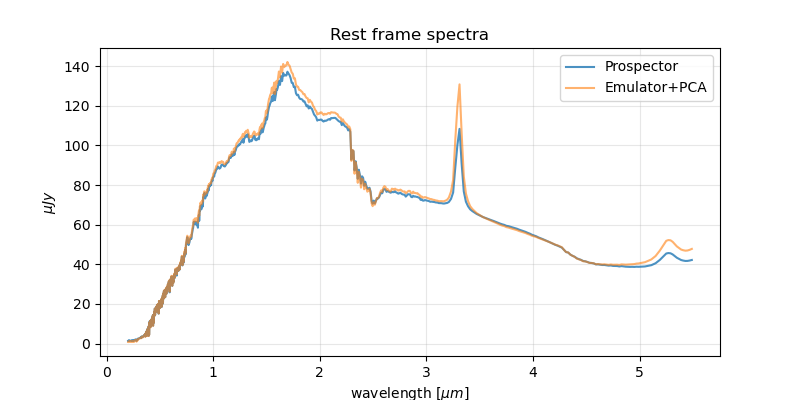

In [39]:
plt.close()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lbs, flux, linewidth=1.5, alpha=0.8, label='Prospector')
ax.plot(lbs, flux_emulator, linewidth=1.5, alpha=0.6, label='Emulator+PCA')
ax.grid(alpha=0.3)
ax.set_xlabel(r'wavelength [$\mu m$]')
ax.set_ylabel(r'$\mu Jy$')
ax.set_title('Rest frame spectra')
ax.legend()

Next, lets say you don't want to install prospector and are interested in inspecting existing spectra, read from a file:  
(again, change the path as needed)

In [71]:
# load validation data; this file contains fluxes, x, c_true, mfrac
val_data = np.load('../random_samples/validation_spectra_x_c_mfrac_10k.npz')
x0_val = val_data['x']
c0_val = val_data['c']
x_val = x_scaler.transform(x0_val)

val_flux_prospector = val_data['flux']

In [42]:
cpredict_10k = model.predict(x_val)
val_flux_emulator = 10**(cpredict_10k @ pca_modes + pca_mean)

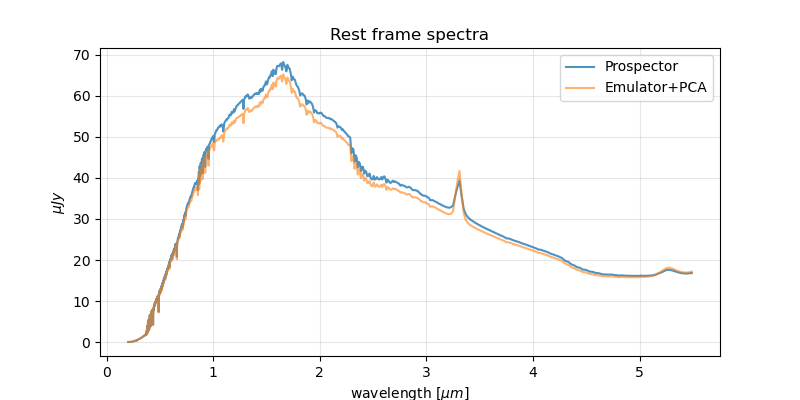

In [46]:
plot_idx = 6

plt.close()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lbs, val_flux_prospector[plot_idx], linewidth=1.5, alpha=0.8, label='Prospector')
ax.plot(lbs, val_flux_emulator[plot_idx], linewidth=1.5, alpha=0.6, label='Emulator+PCA')
ax.grid(alpha=0.3)
ax.set_xlabel(r'wavelength [$\mu m$]')
ax.set_ylabel(r'$\mu Jy$')
ax.set_title('Rest frame spectra')
ax.legend()

## Training

Below is how I trained the emulator. 

Let's read the 100k random parameters I generated previously using appropriate priors:

In [47]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

I have already compiled 100k galaxies, and converted their input prospector parameters to emulator compatible format `x`

In [ ]:
train_inputs_outputs = np.load('../random_samples/train_x_c_mfrac_100k.npz')
x0 = train_inputs_outputs['x']  
# this is the input prospector parameters already convert to emulator input format, for convenience, since it's a hassle to do that
# this file also contains PCA coefficients c from the PCA modes above, though we will not use it here

# start fresh with everything, including scaler
new_x_scaler = StandardScaler()
x = new_x_scaler.fit_transform(x0)

We'll also read the spectra ran from prospector so we don't have to re-run slowly.  
We should get the `logflux` since we want to derive PCA with them

In [49]:
train_spectra_file = np.load('../random_samples/train_spectra_100k.npz')
train_logflux = train_spectra_file['logflux']

In [50]:
nc = 20
pca = PCA(n_components=nc)
coefs = pca.fit_transform(train_logflux)       # this is the pca coefficient of each training galaxy, which we use as training output
# this rcoefs are the same you get from 'input_output_100k.npz'['c']

seds_transform = pca.inverse_transform(coefs) # this givees you reconstructed spectra
new_modes = pca.components_
new_mean = pca.mean_

Define a new emulator, train on input `x` and newly derived PCA coefficients `coefs`

In [51]:
nlayers = 3
nneurons = 256

new_model = MLPRegressor(
    hidden_layer_sizes=(nneurons, )*nlayers,
    activation="relu",
    solver="adam",
    learning_rate_init=1e-3,
    batch_size=1000,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=40,
    random_state=42,
    verbose=True
)

new_model.fit(x, coefs)

Iteration 1, loss = 222.66204850
Validation score: -1.325196
Iteration 2, loss = 29.70197996
Validation score: -0.802705
Iteration 3, loss = 23.00324350
Validation score: -0.413251
Iteration 4, loss = 18.56048120
Validation score: -0.252583
Iteration 5, loss = 14.01675752
Validation score: -0.215163
Iteration 6, loss = 10.62510485
Validation score: -0.197244
Iteration 7, loss = 8.58191759
Validation score: -0.159444
Iteration 8, loss = 7.23464035
Validation score: -0.082025
Iteration 9, loss = 6.32374416
Validation score: -0.059583
Iteration 10, loss = 5.58240522
Validation score: 0.054820
Iteration 11, loss = 5.03962895
Validation score: -0.146636
Iteration 12, loss = 4.52932912
Validation score: 0.054583
Iteration 13, loss = 4.17898924
Validation score: 0.050735
Iteration 14, loss = 3.94888780
Validation score: 0.022727
Iteration 15, loss = 3.63486218
Validation score: -0.124689
Iteration 16, loss = 3.46629459
Validation score: 0.102080
Iteration 17, loss = 3.26134242
Validation scor

,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(256, ...)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",1000
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",500
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


Use this new model to evaluate the random galaxy we generate from the beginning

In [52]:
# first transform it with new scaler, remember to add an axis
x_new = new_x_scaler.transform(x0_test[None,:])

# feed it to new_model to get predicted PCA coefficient
c_new = new_model.predict(x_new)
flux_emulator_new = 10 ** (c_new[0] @ new_modes + new_mean)

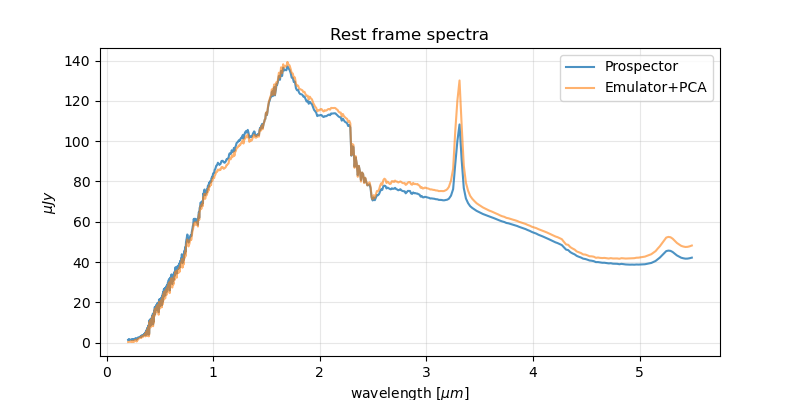

In [53]:
plt.close()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lbs, flux, linewidth=1.5, alpha=0.8, label='Prospector')
ax.plot(lbs, flux_emulator_new, linewidth=1.5, alpha=0.6, label='Emulator+PCA')
ax.grid(alpha=0.3)
ax.set_xlabel(r'wavelength [$\mu m$]')
ax.set_ylabel(r'$\mu Jy$')
ax.set_title('Rest frame spectra')
ax.legend()

## Evaluation from validation set

Now use the full 10k validation set to evaluate the new emulator.

There are 4 metrics I defined here:
1. per galaxy relative L2 error: |flux_true-flux_predict|_2 / |flux_true|_2
2. per galaxy mean absolute error: |flux_true-flux_predict| / flux_predict
3. median ratio: median(flux_predict/flux_true)
4. Full sample PCA coefficient MSE: 1/N_validation * sum((coef_true - coef_predict)**2)

In [75]:
nsample_val = x_val.shape[0]

# since we re-derive the PCA modes and mean, let's re-calculate the c_true for validation data
c0_val_new = (np.log10(val_flux_prospector) - new_mean) @ new_modes.T

# Get all the predicted coefficients
c0_val_predict = new_model.predict(x_val)
mse = np.linalg.norm(c0_val_new - c0_val_predict)**2 / nsample_val

In [76]:
# calculate the errors and MSE
rel_l2_errs = np.zeros(nsample_val)
mean_abs_errs = np.zeros(nsample_val)
median_ratios = np.zeros(nsample_val)

for i in range(nsample_val):
    flux_pros = val_flux_prospector[i]
    flux_emu = 10**(c0_val_predict[i] @ new_modes + new_mean)   # remember to use the new PCA modes

    rel_l2_errs[i] = np.linalg.norm(flux_pros-flux_emu)/np.linalg.norm(flux_pros)
    mean_abs_errs[i] = np.mean(np.abs((flux_pros-flux_emu))/flux_pros)
    median_ratios[i] = np.median(flux_emu/flux_pros)

Plotting several error metrics and distributions.  

We can see at low redshift (<0.05) it really struggled, potentially because redshift dimming is hard for the model to emulate. 

There is also a slight trend of ratio w.r.t logmass, suggesting emulator didn't model the mass scaling properly. This more or less goes away when we have more neurons.  

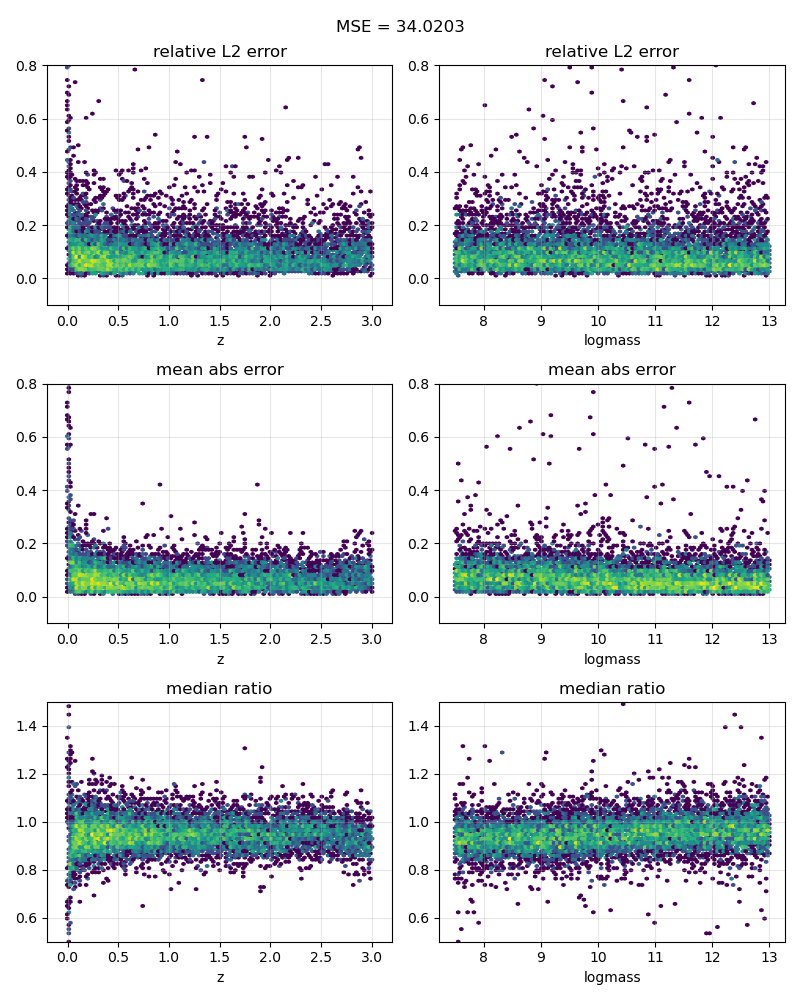

In [77]:
features_val = x0_val.T
idx_sort = np.argsort(x0_val[:,0])[::-1]

plt.close()
fig, ax = plt.subplots(3, 2, figsize=(8, 10))
# ax[0,0].scatter(features_val[0], rel_l2_errs, s=3, alpha=0.3)
ax[0,0].hexbin(features_val[0], rel_l2_errs, extent=[-0.05, 3.05, -0.1, 0.8], bins='log')
ax[0,0].set_xlabel('z')
ax[0,0].set_ylim(-0.1, 0.8)
ax[0,0].grid(alpha=0.3)
ax[0,0].set_title('relative L2 error')

# ax[0,1].scatter(features_val[1], rel_l2_errs, s=3, alpha=0.3)
ax[0,1].hexbin(features_val[1], rel_l2_errs, extent=[7.5, 13, -0.1, 0.8], bins='log')
ax[0,1].set_xlabel('logmass')
ax[0,1].set_ylim(-0.1, 0.8)
ax[0,1].grid(alpha=0.3)
ax[0,1].set_title('relative L2 error')

# ax[1,0].scatter(features_val[0], mean_abs_errs, s=3, alpha=0.3)
ax[1,0].hexbin(features_val[0], mean_abs_errs, extent=[-0.05, 3.05, -0.1, 0.8], bins='log')
ax[1,0].set_xlabel('z')
ax[1,0].set_ylim(-0.1, 0.8)
ax[1,0].grid(alpha=0.3)
ax[1,0].set_title('mean abs error')

# ax[0,1].scatter(features_val[1], mean_abs_errs, s=3, alpha=0.3)
ax[1,1].hexbin(features_val[1], mean_abs_errs, extent=[7.5, 13, -0.1, 0.8], bins='log')
ax[1,1].set_xlabel('logmass')
ax[1,1].set_ylim(-0.1, 0.8)
ax[1,1].grid(alpha=0.3)
ax[1,1].set_title('mean abs error')

# ax[2,0].scatter(features_val[0], median_ratios, s=3, alpha=0.3)
ax[2,0].hexbin(features_val[0], median_ratios, extent=[-0.05, 3.05, 0.5, 1.5], bins='log')
ax[2,0].grid(alpha=0.3)
ax[2,0].set_ylim(0.5, 1.5)
ax[2,0].set_xlabel('z')
ax[2,0].set_title('median ratio')

# ax[2,1].scatter(features_val[1], median_ratios, s=3, alpha=0.3)
ax[2,1].hexbin(features_val[1], median_ratios, extent=[7.5, 13, 0.5, 1.5], bins='log')
ax[2,1].grid(alpha=0.3)
ax[2,1].set_ylim(0.5, 1.5)
ax[2,1].set_xlabel('logmass')
ax[2,1].set_title('median ratio')

fig.suptitle(f'MSE = {mse:.4f}')
fig.tight_layout()